# 0. Imports and defaults

In [1]:
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Import the public function from the package you completed
from energy_model import model_run

In [2]:
# Default parameters for testing

# input database folder
db_dir = 'input_databases//default'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h

# NEW: subsidy growth 
subsidy_growth_base = -0.50
subsidy_growth_high = 0.0 
subsidy_growth_low = -0.100 


# NEW: demand parameters (insulation parameters)
# saturation: max share of highly insulated houses
K_base  = 0.70    
K_high = 0.90  
K_low = 0.50 

s0 = 0.26    # share of highly insulated houses at t = 0 
r  = 0.032   # growth rate 
R  = 0.32    # demand reduction for highly insulated houses 
T0 = 2020   # reference year, so t = model_year - 2020


In [3]:
# Handy plotting functions

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1,2)
    fig.set_size_inches(16,8)

    for n,c in enumerate([# 'Residential electricity',
            'Residential heat high',
            'Residential heat low',
            # 'Transportation',
            # 'Industrial machinery',
            # 'Industrial HTP'
            ]): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20',ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

# This function was not used in the final presentation, but we kept it in case of need
def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20', ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


# 1. Model Run

In [4]:
base = model_run(db_dir,years,t_res,passenger_cars_cf,rt,rs, subsidy_growth_base, K_base, s0, r, R, T0)
base.name = 'base'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 425.79it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-xs437qk5.lp
Reading time = 0.46 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694901008e+20


In [5]:
# High insulation, high subsidy scenario 
tandem = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_high, K_high, s0, r, R, T0)
tandem.name = 'tandem'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 480.65it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-8e7_nh74.lp
Reading time = 0.41 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694804355e+20


In [6]:
# High insulation, low subsidy scenario 
one_way_lane = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_low, K_high, s0, r, R, T0)
one_way_lane.name = 'One way lane'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 494.38it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-9ogfzk1h.lp
Reading time = 0.42 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694809016e+20


In [7]:
# Low insulation, high subsidy scenario 
uphill_ride = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_high, K_low, s0, r, R, T0)
uphill_ride.name = 'Uphill ride'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 336.25it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-j8zjm6fx.lp
Reading time = 0.41 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694965159e+20


In [8]:
# Low insulation, low subsidy scenario 
flat_tire = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs, subsidy_growth_low, K_low, s0, r, R, T0)
flat_tire.name = 'Flat tire'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 359.71it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-mbg1hqey.lp
Reading time = 0.41 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694968528e+20


# 2. Plots

## 2.1 Helper functions

In [9]:
# Helper functions  
import warnings
from pathlib import Path

# I need to import preprocess_technologies to use the function total_subsidy_spent 
from energy_model.model import total_subsidy_spent
from energy_model.preprocessing import preprocess_technologies 

techs_s, techs_d, cn = preprocess_technologies(db_dir, years, passenger_cars_cf)


# Runs used: 
runs = {                      
    "Baseline": base,
    "Tandem": tandem,
    "One-way lane": one_way_lane,
    "Uphill ride": uphill_ride,
    "Flat tire": flat_tire
}

EMISSIONS_BUS = "Emissions"  

HEAT_BUSES = ["Residential heat high", "Residential heat low"]
HP_CARRIERS = ["Residential heat pump"]

def boiler_carriers(n):
    # includes the "- existing" boilers, which still deliver heat
    return [c for c in n.links.carrier.unique() if "Residential gas boiler" in c]

def heat_delivered(n, carriers):
    links = n.links.index[n.links.carrier.isin(carriers)]
    w = n.snapshot_weightings.generators
    total = pd.Series(0.0, index=n.snapshots)
    for port in ["1", "2", "3"]:
        buses = n.links.loc[links, f"bus{port}"].astype(str)
        sel = buses.index[buses.isin(HEAT_BUSES)]
        if len(sel):
            total = total + (-getattr(n.links_t, f"p{port}")[sel].sum(axis=1))
    return (total * w).groupby(level=0).sum()

def adoption(n):
    hp = heat_delivered(n, HP_CARRIERS)
    boiler = heat_delivered(n, boiler_carriers(n))
    return hp / (hp + boiler)


# Get final emissions 
def extract_emissions(n):
    final_year = n.investment_periods[-1]
    return n.stores_t.e.loc[final_year, "CO2 atmosphere"].iloc[-1]

# Get final system cost 
def total_cost(n):
    return n.objective 

METRICS = {
    "emissions": lambda n, sg: extract_emissions(n),
    "cost":      lambda n, sg: total_cost(n),
    "subsidy":   lambda n, sg: total_subsidy_spent(n, techs_d, rt, sg),
}

def run_sweep(model_run, subsidy_growth_values, K_values, metrics=METRICS, **run_kwargs):
    rows = []
    for sg in subsidy_growth_values:
        for K in K_values:
            try:
                n = model_run(subsidy_growth=sg, K=K, **run_kwargs)
                vals = {name: float(fn(n, sg)) for name, fn in metrics.items()}
            except Exception as exc:
                warnings.warn(f"Run failed (subsidy_growth={sg}, K={K}): {exc}")
                vals = {name: np.nan for name in metrics}
            rows.append({"subsidy_growth": sg, "K": K, **vals})
    return pd.DataFrame(rows)


def plot_heatmap(df, metric, subsidy_growth_values, K_values,
                 scale=1.0, cbar_label=None, cmap="viridis_r",
                 fmt=".1f", baseline=None):
    """Heatmap of one metric column from run_sweep's DataFrame."""
    z = np.ma.masked_invalid(
        df.pivot(index="K", columns="subsidy_growth", values=metric)
          .reindex(index=K_values, columns=subsidy_growth_values)
          .to_numpy() * scale
    )

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("lightgrey")
    im = ax.imshow(z, origin="lower", aspect="auto", cmap=cm)

    ax.set_xticks(range(len(subsidy_growth_values)))
    ax.set_xticklabels([f"{v:.0%}" for v in subsidy_growth_values])
    ax.set_yticks(range(len(K_values)))
    ax.set_yticklabels([f"{v:.0%}" for v in K_values])
    ax.set_xlabel("Heat-pump subsidy growth")
    ax.set_ylabel("K (max. share of well-insulated homes)")
    fig.colorbar(im, ax=ax, label=cbar_label or metric)

    zmin, zmax = z.min(), z.max()
    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            if np.ma.is_masked(z[i, j]):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=8)
            else:
                dark = (z[i, j] - zmin) / (zmax - zmin + 1e-12) > 0.5
                ax.text(j, i, format(z[i, j], fmt), ha="center", va="center",
                        fontsize=8, color="white" if dark else "black")

    if baseline is not None:
        bj = np.flatnonzero(np.isclose(subsidy_growth_values, baseline[0]))
        bi = np.flatnonzero(np.isclose(K_values, baseline[1]))
        if len(bj) and len(bi):
            ax.add_patch(plt.Rectangle((bj[0] - 0.5, bi[0] - 0.5), 1, 1,
                                       fill=False, edgecolor="red", linewidth=2.5))

    fig.tight_layout()
    plt.show()
    return fig, ax

## 2.2 Energy Balance

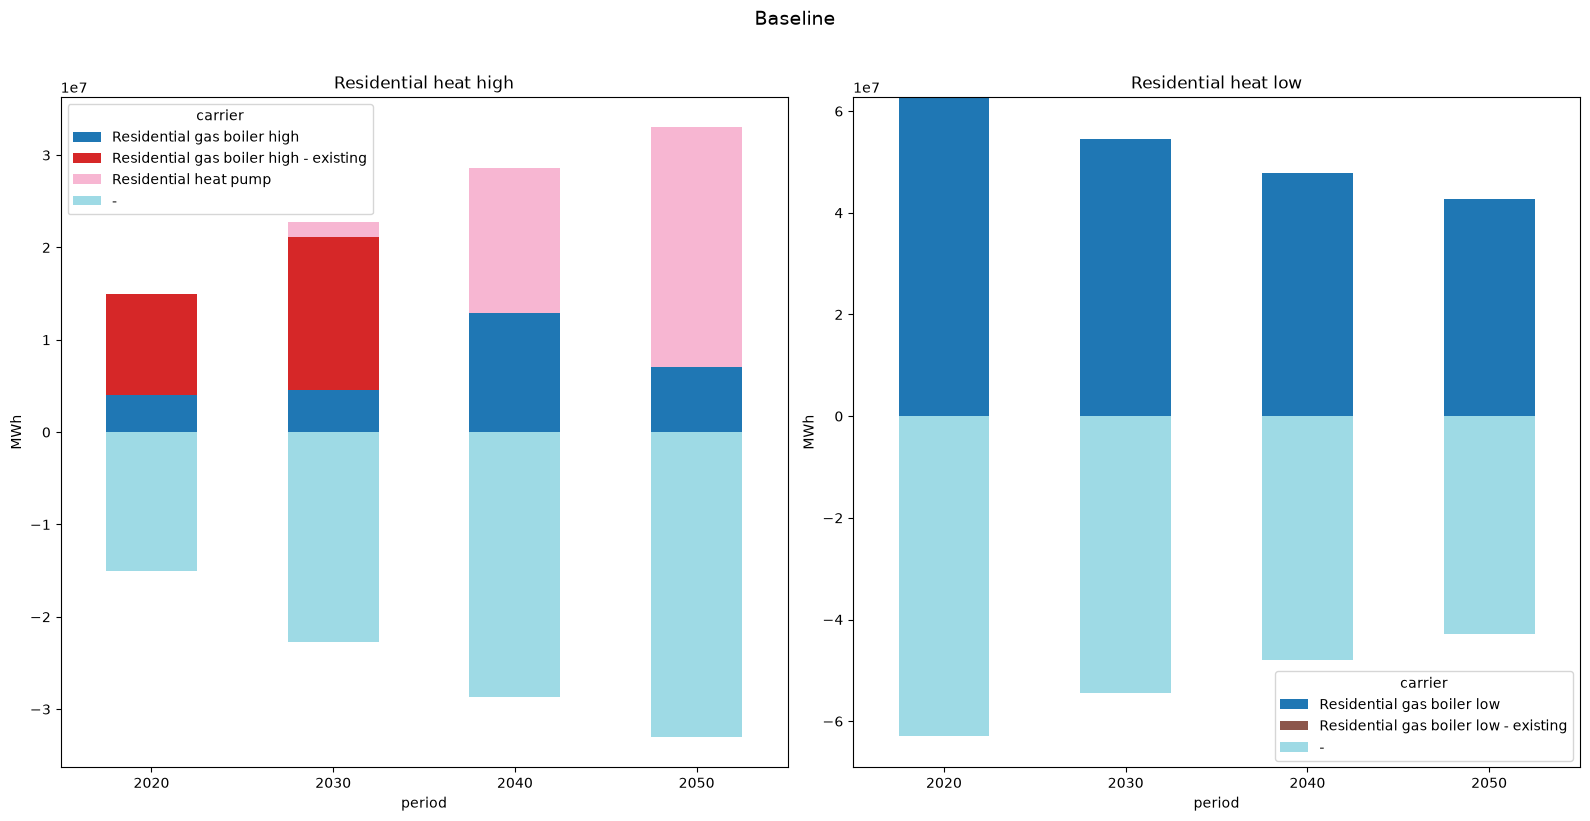

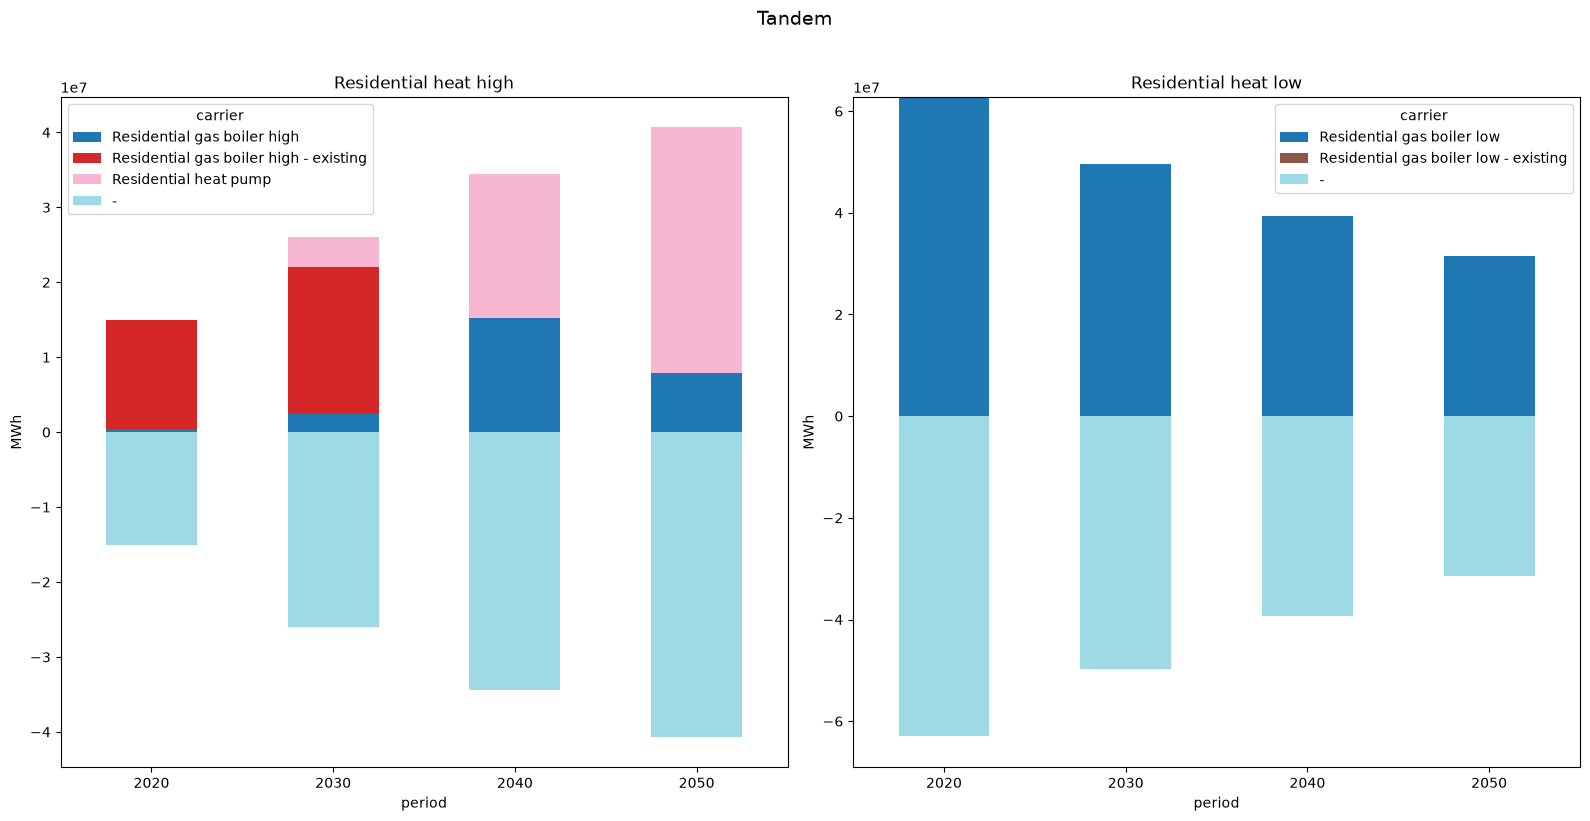

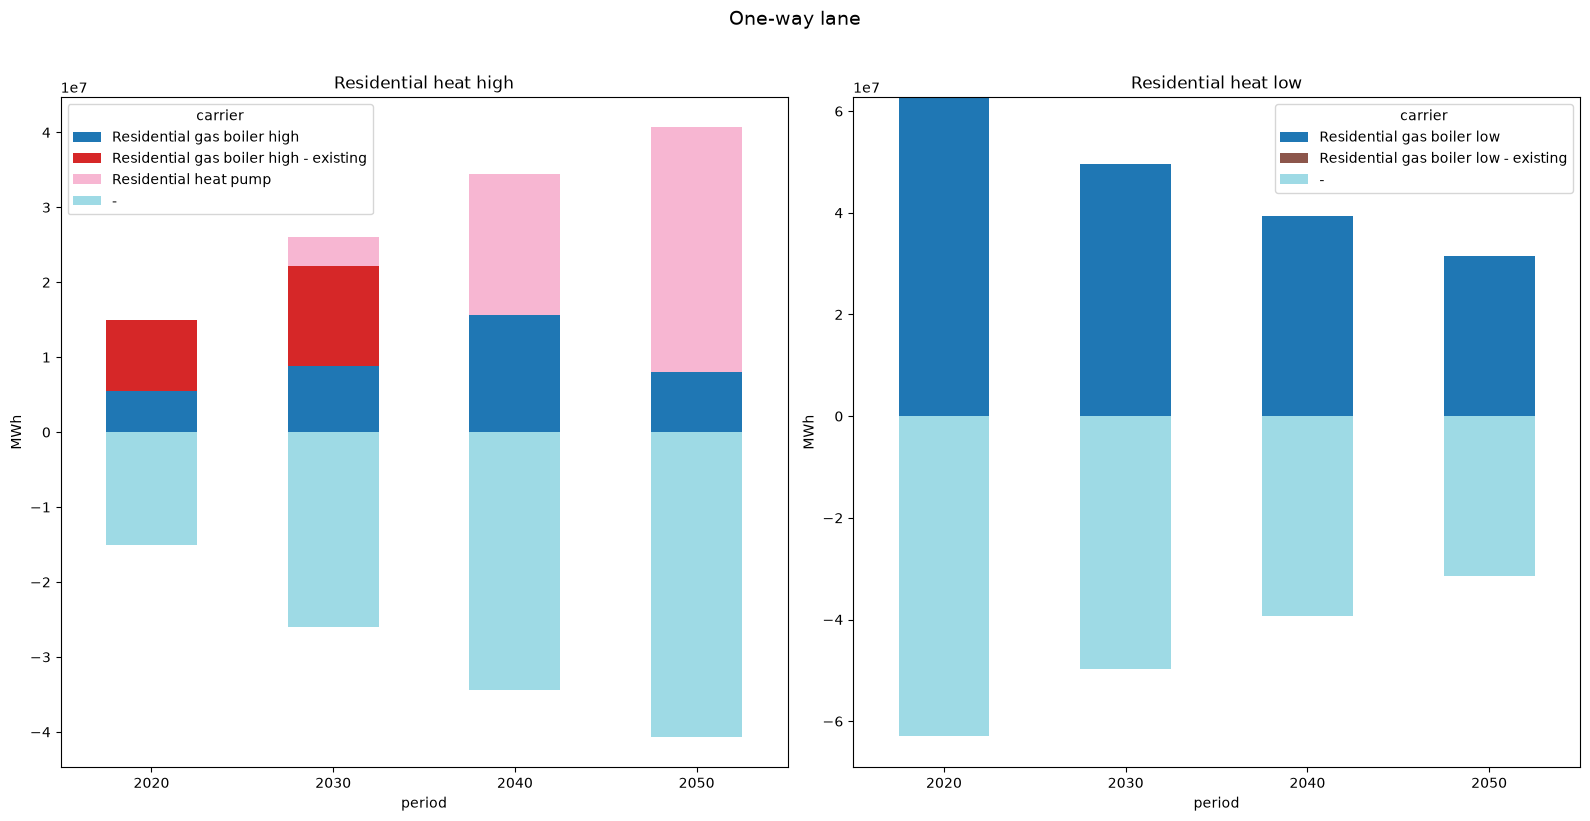

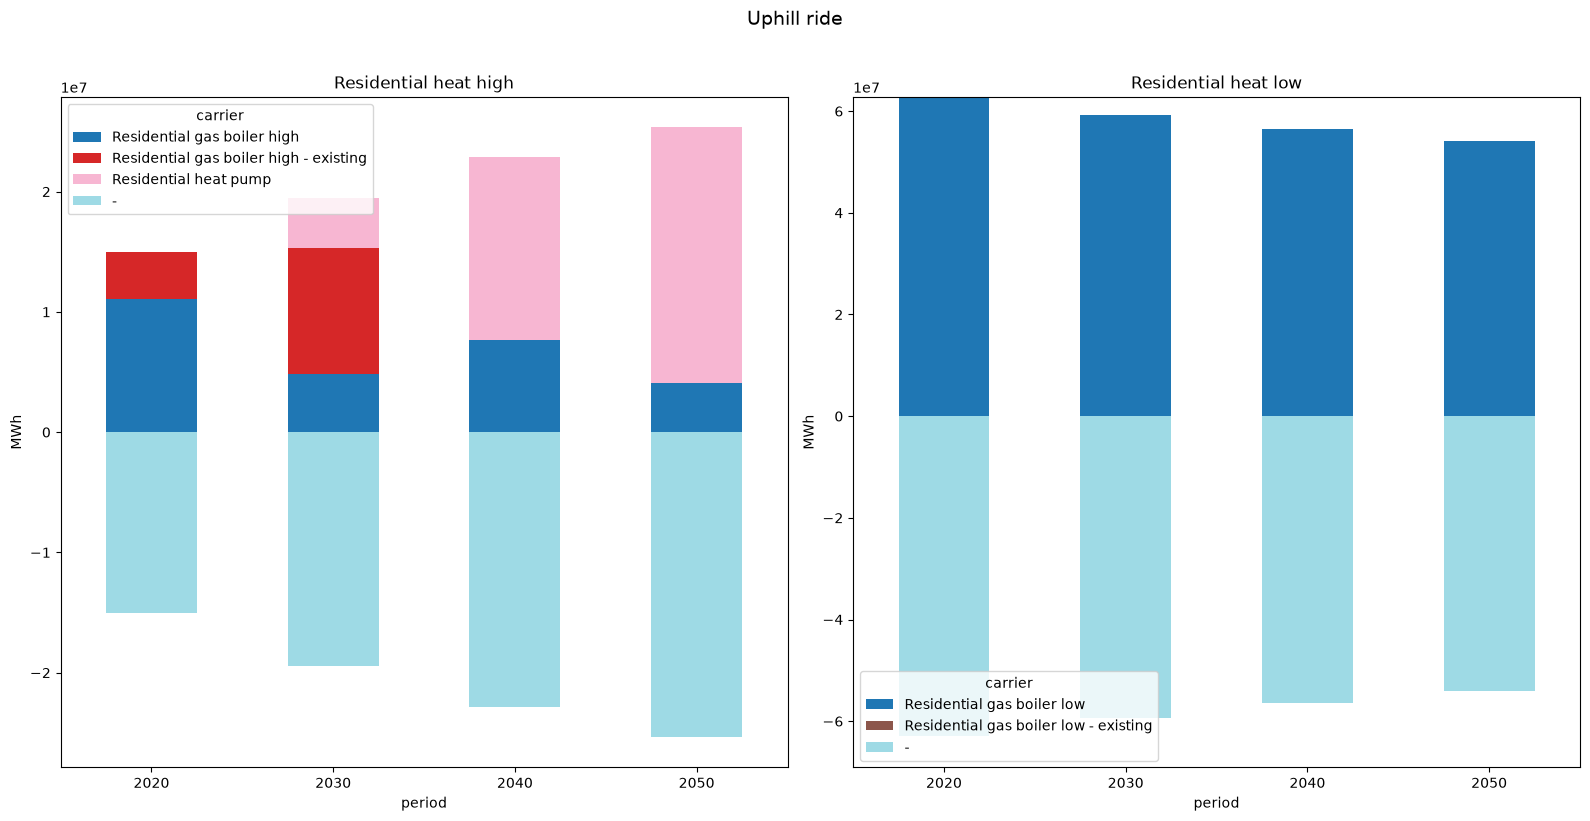

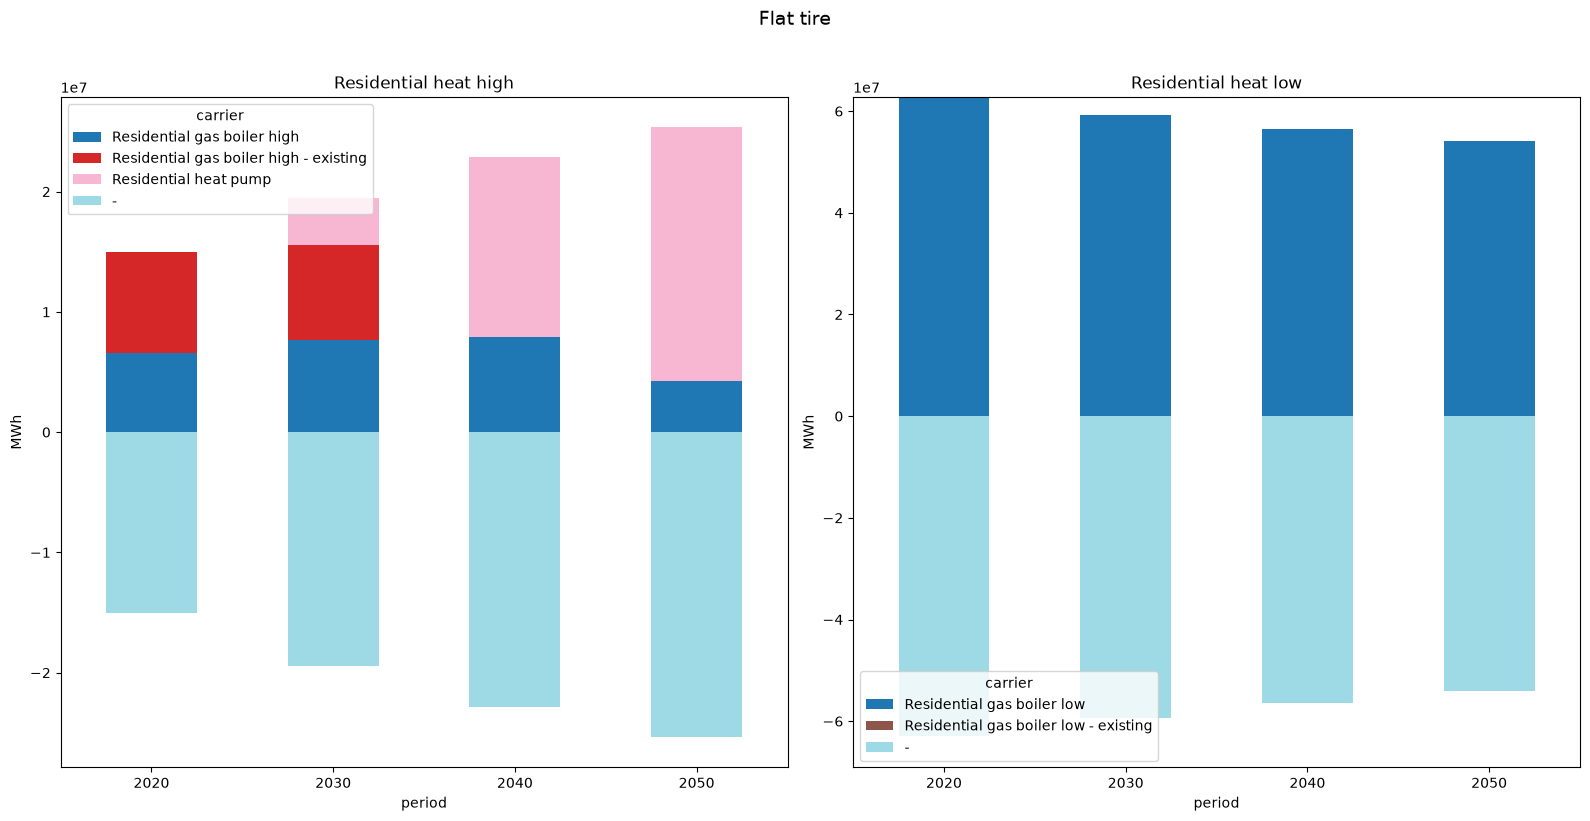

In [10]:
for name, n in runs.items():
    plot_main_ebs(n)
    fig = plt.gcf()
    fig.suptitle(name, fontsize=14, y=1.02)   # title on top of the whole figure
    fig.tight_layout()
    plt.show()

## 2.3 Line plot 

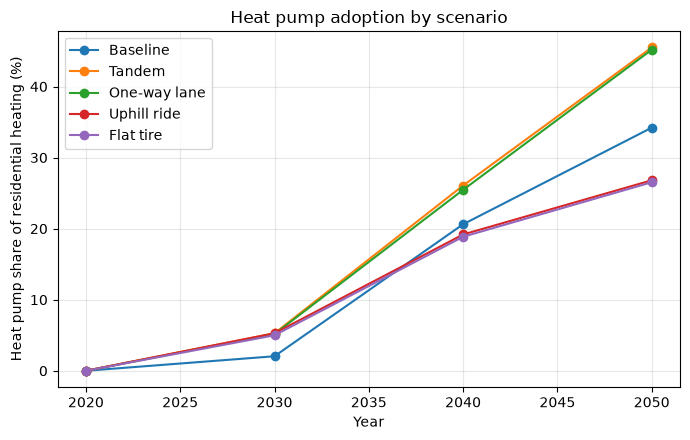

In [11]:
# 1) Line plot: adoption speed, one line per scenario
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, n in runs.items():
    s = adoption(n)
    ax.plot(s.index, s.values * 100, marker="o", label=name)
ax.set_xlabel("Year")
ax.set_ylabel("Heat pump share of residential heating (%)")
ax.set_title("Heat pump adoption by scenario")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.4 Scatter plot - costs
Total costs for everyone

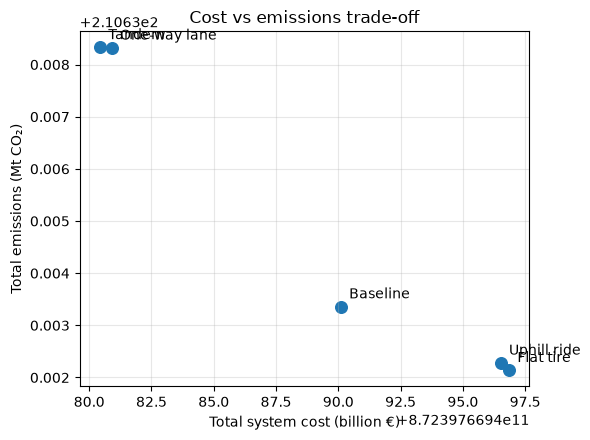

In [12]:
# Scatter plot: cost vs emissions, one dot per scenario
res = pd.DataFrame(
    {name: {"cost": total_cost(n), "emissions": extract_emissions(n)}
     for name, n in runs.items()}
).T

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(res["cost"] / 1e9, res["emissions"] / 1e6, s=70)
for name, row in res.iterrows():
    ax.annotate(name, (row["cost"] / 1e9, row["emissions"] / 1e6),
                textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("Total system cost (billion €)")
ax.set_ylabel("Total emissions (Mt CO₂)")
ax.set_title("Cost vs emissions trade-off")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.5 Scatter plot - subsidies 
Total cost subsidies 

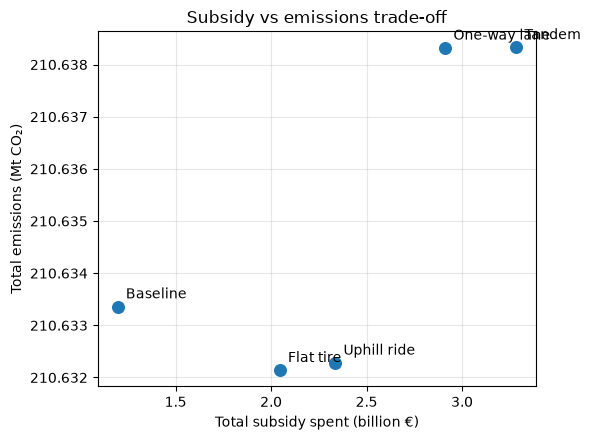

In [13]:
# which subsidy growth each run was solved with
growth_per_run = {                      
    "Baseline": subsidy_growth_base,
    "Tandem": subsidy_growth_high,
    "One-way lane": subsidy_growth_low,
    "Uphill ride": subsidy_growth_high,
    "Flat tire": subsidy_growth_low
}  # <- adjust to what each run actually used

res = pd.DataFrame(
    {name: {"total_subsidy": total_subsidy_spent(n, techs_d, rt, growth_per_run[name]),
            "emissions": extract_emissions(n)}
     for name, n in runs.items()}
).T

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(res["total_subsidy"] / 1e9, res["emissions"] / 1e6, s=70)
for name, row in res.iterrows():
    ax.annotate(name, (row["total_subsidy"] / 1e9, row["emissions"] / 1e6),
                textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("Total subsidy spent (billion €)")
ax.set_ylabel("Total emissions (Mt CO₂)")
ax.set_title("Subsidy vs emissions trade-off")
ax.ticklabel_format(useOffset=False, style="plain")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 2.5 Heat map emissions 

In [14]:
# First we need to determine values and run_sweep
subsidy_growth_values = [ -1.0, -0.75, -0.50, -0.25, 0.0]
K_values = [.50, .60, .70, .80, .90]
base_sg = -0.50
base_K = 0.70

df = run_sweep(
    model_run, subsidy_growth_values, K_values,
    db_dir=db_dir, years=years, t_res=t_res,
    passenger_cars_cf=passenger_cars_cf,
    rt=rt, rs=rs, s0=s0, r=r, R=R, T0=T0,
)

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 375.13it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-ggu1ue8d.lp
Reading time = 0.42 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.72397669499486e+20
2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 94.35it/s]


...

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-d0uaop3v.lp
Reading time = 0.47 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694881806e+20
2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 180.81it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-53nv2lxs.lp
Reading time = 0.56 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694843082e+20
2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 326.96it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-x9hpu642.lp
Reading time = 0.46 seconds
obj: 291510 rows, 134991 columns, 670358 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 8.723976694804355e+20


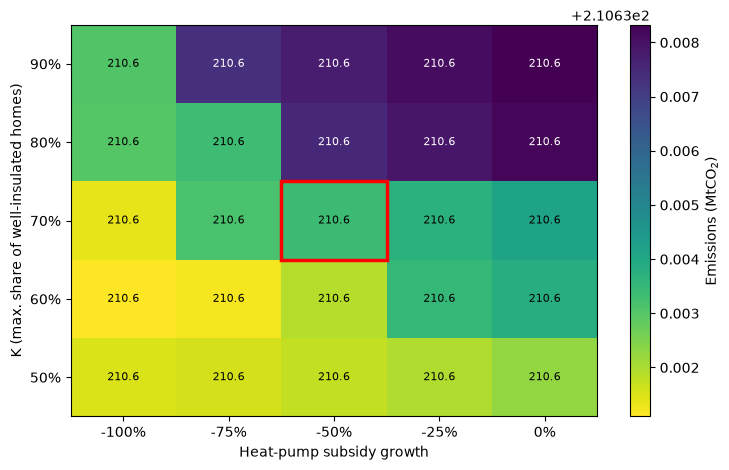

(<Figure size 750x480 with 2 Axes>,
 <Axes: xlabel='Heat-pump subsidy growth', ylabel='K (max. share of well-insulated homes)'>)

In [15]:
# Heat map emissions
plot_heatmap(df, "emissions", subsidy_growth_values, K_values,
             scale=1e-6, cbar_label="Emissions (MtCO$_2$)",
             baseline=(base_sg, base_K))

## 2.6 Heat map costs 

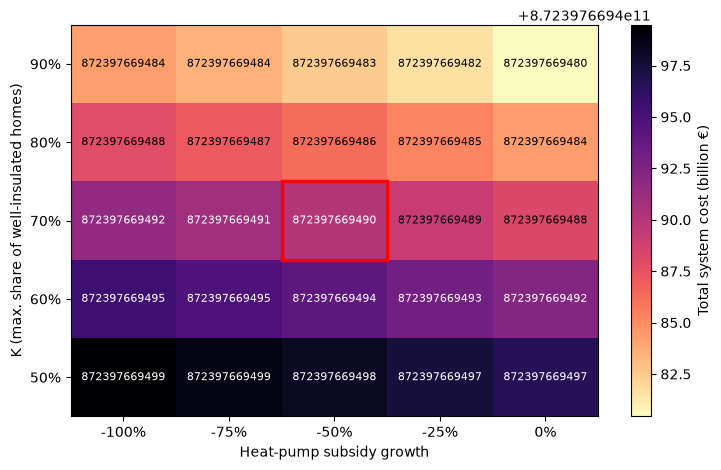

(<Figure size 750x480 with 2 Axes>,
 <Axes: xlabel='Heat-pump subsidy growth', ylabel='K (max. share of well-insulated homes)'>)

In [16]:
# 4) Heat map for costs 
plot_heatmap(df, "cost", subsidy_growth_values, K_values,
             scale=1e-9, cbar_label="Total system cost (billion €)",
             cmap="magma_r", fmt=".0f",
             baseline=(base_sg, base_K))

## 2.7 Heat map subsidy 

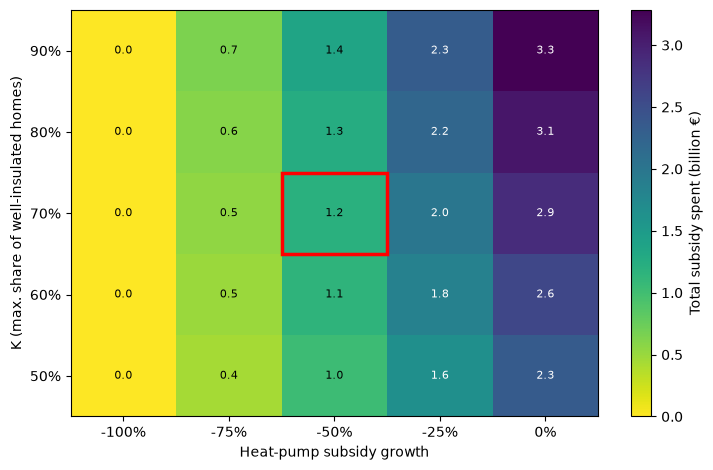

(<Figure size 750x480 with 2 Axes>,
 <Axes: xlabel='Heat-pump subsidy growth', ylabel='K (max. share of well-insulated homes)'>)

In [17]:
plot_heatmap(df, "subsidy", subsidy_growth_values, K_values,
             scale=1e-9, cbar_label="Total subsidy spent (billion €)",
             baseline=(base_sg, base_K))